In [1]:
import pandas as pd
#DATA UNDERSTANDING AND GRAPHS
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns


import pickle

# DATA PREPARATION
import nltk
from nltk.tokenize import word_tokenize
from nltk.tag import pos_tag
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re
import ast
from collections import Counter

from nltk.util import ngrams
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet


# OUR FUNCTIONS
from utils.visualizations import get_clean_words, extract_words
from langdetect import detect
from utils.functions_eda_preproc import verify_language, clean_text, normalize_text

import os
import pickle
import re
import nltk
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import plotly.express as px
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score
from tqdm import tqdm
from wordcloud import WordCloud
from mittens import GloVe
from gensim.models import Word2Vec
import utils.visualizations as visualizations
import importlib
importlib.reload(visualizations)
from utils.visualizations import word_cloud_generator, show_saved_images,cooccurrence_matrix_sentence_generator, plot_genre_cooccurrence, d2_embeddings_plotter

from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import MultinomialNB
!pip install scikit-learn
from sklearn.naive_bayes import MultinomialNB


from utils.functions_vectors_modelling import evaluate_models, document_vector
import warnings
warnings.filterwarnings('ignore')


In [2]:
train = pd.read_csv('./Datasets/train.csv', index_col = 'id')
test = pd.read_csv('./Datasets/test.csv',index_col = 'id')
train.head()

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\r\nDid you mean it ...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\r\n[Hook]\r\nEverybody wants yo...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\r\nPeople tell me I've changed\r\nI ...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\r\nDon't try to ge...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\r\nI can see the end is coming but I...


In [3]:
train = train.rename(columns={'lyrics': 'raw_lyrics'})
test = test.rename(columns={'lyrics': 'raw_lyrics'})


In [4]:
train.drop_duplicates(subset=['raw_lyrics'], keep='first', inplace=True)

train.reset_index(drop=True, inplace=True)
print(f"Train dataset shape after removing duplicates: {train.shape}")

Train dataset shape after removing duplicates: (134789, 7)


In [5]:
train['lyrics_cleaned']= clean_text(train, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, apostrophes=True, whitespaces=True)

In [6]:
test['lyrics_cleaned']= clean_text(test, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, whitespaces=True)

In [7]:
train['lyrics_normalized'] = train['lyrics_cleaned'].apply(
    lambda x: normalize_text(
        x, 
        custom_stopwords= None,
        tokenized_output=False))

In [8]:
test['lyrics_normalized'] = test['lyrics_cleaned'].apply(
    lambda x: normalize_text(x,
        custom_stopwords= None,
        tokenized_output=False))

In [9]:
X = train["lyrics_normalized"].fillna("").astype(str)
y = train["tag"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training subset: {len(X_train):,} songs")
print(f"Validation subset: {len(X_val):,} songs")

Training subset: 107,831 songs
Validation subset: 26,958 songs


In [ ]:
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

def evaluate_models(X_train_vec, X_test_vec, y_train, y_test, representation_name):
    models = {
        'Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'SGD Classifier (SVM)': SGDClassifier(class_weight='balanced', loss='hinge', max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=50, random_state=42, n_jobs=-1)
    }
    
    results = []
    
    for name, model in models.items():
        # Verifica valores negativos de forma segura tanto em matrizes esparsas (BoW/TF-IDF) como densas (Word2Vec/GloVe)
        has_negative = (X_train_vec < 0).nnz > 0 if hasattr(X_train_vec, "nnz") else (X_train_vec < 0).any()
        if name == 'Naive Bayes' and has_negative:
            print(f"A saltar {name} (não aceita valores negativos nas representações densas).")
            continue
            
        print(f"Training {name} with {representation_name}...")
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)
      
        score = f1_score(y_test, preds, average='macro')
        
        results.append({
            'Representation': representation_name,
            'Model': name,
            'Macro F1-Score': round(score, 4)
        })
        
    return pd.DataFrame(results).sort_values(by='Macro F1-Score', ascending=False)

In [11]:
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 2), 
    token_pattern=r"(?u)\b\w+\b",
    min_df=5,
    max_features=10000,
)


X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)


results_bow = evaluate_models(X_train_bow, X_val_bow, y_train, y_val, "Bag of Words")
display(results_bow)

Training Naive Bayes with Bag of Words...
Training Logistic Regression with Bag of Words...
Training SGD Classifier (SVM) with Bag of Words...
Training Random Forest with Bag of Words...


,Representation,Model,Macro F1-Score
0,Bag of Words,Naive Bayes,0.4383
2,Bag of Words,SGD Classifier (SVM),0.4220
1,Bag of Words,Logistic Regression,0.3988
3,Bag of Words,Random Forest,0.3653


In [12]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    token_pattern=r"(?u)\b\w+\b",
    min_df=5,
    max_features=10000,
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)


results_tfidf = evaluate_models(X_train_tfidf, X_val_tfidf, y_train, y_val, "TF-IDF")
display(results_tfidf)

Training Naive Bayes with TF-IDF...
Training Logistic Regression with TF-IDF...
Training SGD Classifier (SVM) with TF-IDF...
Training Random Forest with TF-IDF...


,Representation,Model,Macro F1-Score
1,TF-IDF,Logistic Regression,0.4466
2,TF-IDF,SGD Classifier (SVM),0.4040
0,TF-IDF,Naive Bayes,0.3994
3,TF-IDF,Random Forest,0.3621


In [13]:
words_train = [lyric.split() for lyric in X_train]
words_val = [lyric.split() for lyric in X_val]

In [14]:
w2v_skipgram = Word2Vec(
    sentences= words_train,
    vector_size=100, 
    window=6, 
    min_count=5, 
    sg=1, 
    workers=4)

X_train_skip = np.array([document_vector(w2v_skipgram.wv, doc) for doc in words_train])
X_val_skip = np.array([document_vector(w2v_skipgram.wv, doc) for doc in words_val])

results_skip = evaluate_models(X_train_skip, X_val_skip, y_train, y_val, "Word2Vec Skip-gram")
display(results_skip)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

A saltar Naive Bayes (não aceita valores negativos nas representações densas).
Training Logistic Regression with Word2Vec Skip-gram...
Training SGD Classifier (SVM) with Word2Vec Skip-gram...
Training Random Forest with Word2Vec Skip-gram...


,Representation,Model,Macro F1-Score
1,Word2Vec Skip-gram,SGD Classifier (SVM),0.4178
0,Word2Vec Skip-gram,Logistic Regression,0.4058
2,Word2Vec Skip-gram,Random Forest,0.4002


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import GridSearchCV, train_test_split

# (Opcional, mas recomendado para não demorar horas) 
# Podes usar a amostra de 30% que testámos há bocadinho:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=0.40, random_state=42, stratify=y_train
)

# 1. Construir o Pipeline integrando a vetorização e o classificador
pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('classifier', SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42))
])

# 2. Definir a grelha alargada
param_grid = [
    {
        'vectorizer': [TfidfVectorizer(), CountVectorizer()],
        'vectorizer__max_df': [0.7, 0.75, 0.80],
        'vectorizer__min_df': [2, 5],
        'vectorizer__ngram_range': [(1, 2), (1, 3)],
        'classifier': [SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__loss': ['hinge', 'log_loss', 'modified_huber'],
        'classifier__alpha': [0.00001,0.0001]
    },
    {
        'vectorizer': [TfidfVectorizer(), CountVectorizer()],
        'vectorizer__max_df': [0.7,0.75, 0.80],
        'vectorizer__min_df': [2, 5],
        'vectorizer__ngram_range': [(1, 2), (1, 3)],
        'classifier': [LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__C': [0.1, 1.0, 10.0]
    }
]

# 3. Configurar o GridSearchCV com verbose=2 (aqui está o segredo para veres o progresso!)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=2   # <--- Alterado de 1 para 2 para cuspir detalhes linha a linha
)

# 4. Executar (usamos a amostra X_train_sample para ser rápido, ou X_train se quiseres os 100%)
grid_search.fit(X_train_sample, y_train_sample)

# 5. Revelar o vencedor
print("Melhor Macro F1-Score na Validação Cruzada:", round(grid_search.best_score_, 4))
print("\nMelhor Modelo e Hiperparâmetros encontrados:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Fitting 3 folds for each of 216 candidates, totalling 648 fits
Melhor Macro F1-Score na Validação Cruzada: 0.4871

Melhor Modelo e Hiperparâmetros encontrados:
  classifier: SGDClassifier(class_weight='balanced', random_state=42)
  classifier__alpha: 1e-05
  classifier__loss: log_loss
  vectorizer: TfidfVectorizer()
  vectorizer__max_df: 0.7
  vectorizer__min_df: 5
  vectorizer__ngram_range: (1, 2)


Macro F1-Score Global: 0.5081



,Género,Precision,Recall,F1-Score,Músicas (Val)
0,rap,0.8541,0.8314,0.8426,7716
1,pop,0.6240,0.6904,0.6555,11120
2,misc,0.5936,0.5756,0.5845,1124
3,rock,0.4755,0.3662,0.4138,5065
4,country,0.2793,0.2958,0.2873,693
5,rb,0.2479,0.2839,0.2647,1240


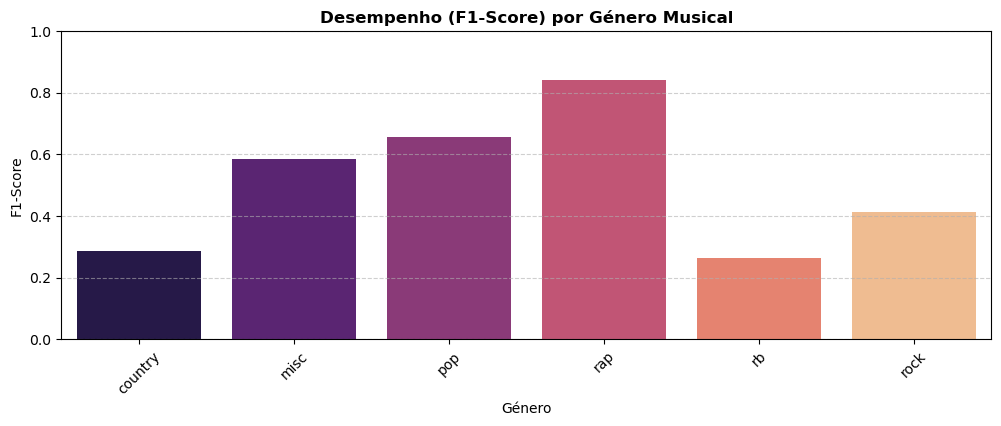

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, f1_score

# Como val_preds já foi calculado antes do erro da linha 18, corre em 0 segundos!
val_f1 = f1_score(y_val, val_preds, average='macro')
print(f"Macro F1-Score Global: {val_f1:.4f}\n")

# Tabela ordenada por F1-Score para cada categoria
report_dict = classification_report(y_val, val_preds, output_dict=True)
genres = sorted(y_val.unique())

df_f1_genres = pd.DataFrame([
    {
        'Género': g,
        'Precision': round(report_dict[g]['precision'], 4),
        'Recall': round(report_dict[g]['recall'], 4),
        'F1-Score': round(report_dict[g]['f1-score'], 4),
        'Músicas (Val)': int(report_dict[g]['support'])
    }
    for g in genres
]).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

display(df_f1_genres)

# Gráfico de barras por género (igual ao que tinhas antes)
plt.figure(figsize=(12, 4))
sns.barplot(data=df_f1_genres.sort_values('Género'), x='Género', y='F1-Score', hue='Género', palette='magma', legend=False)
plt.title('Desempenho (F1-Score) por Género Musical', fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.show()

In [23]:
import os
import pandas as pd
from sklearn.metrics import f1_score, classification_report

# 1. Treinar o vencedor nos 100% do X_train e prever no X_val
best_model = grid_search.best_estimator_  # (se usares GridSearchCV, troca por grid_search.best_estimator_)
best_model.fit(X_train, y_train)
val_preds = best_model.predict(X_val)

# 2. Calcular e mostrar o Macro F1-Score Global + parâmetros vencedores
val_f1 = f1_score(y_val, val_preds, average='macro')
print(f"Macro F1-Score Global: {val_f1:.4f}")
print("Melhores parâmetros:", grid_search.best_params_, "\n")

# 3. Ver o F1-Score de cada género numa tabela limpa
report = classification_report(y_val, val_preds, output_dict=True)
df_generos = pd.DataFrame([
    {"Género": g, "F1-Score": round(report[g]["f1-score"], 4)}
    for g in sorted(y_val.unique())
]).sort_values(by="F1-Score", ascending=False)
display(df_generos)

# 4. Guardar tudo (Global + por género + parâmetros) no CSV ordenado pelo melhor Macro_F1
linha = pd.DataFrame([{
    "Teste": "teste_só_remover_duplicados",  # <-- nos próximos notebooks só mudas este nome
    "Macro_F1": round(val_f1, 4),
    "country": round(report["country"]["f1-score"], 4),
    "rb": round(report["rb"]["f1-score"], 4),
    "pop": round(report["pop"]["f1-score"], 4),
    "rock": round(report["rock"]["f1-score"], 4),
    "misc": round(report["misc"]["f1-score"], 4),
    "rap": round(report["rap"]["f1-score"], 4),
    "Params": str(grid_search.best_params_)
}])

linha.to_csv("meus_resultados.csv", mode="a", header=not os.path.exists("meus_resultados.csv"), index=False)
display(pd.read_csv("meus_resultados.csv").sort_values(by="Macro_F1", ascending=False))

Macro F1-Score Global: 0.5081
Melhores parâmetros: {'classifier': SGDClassifier(class_weight='balanced', random_state=42), 'classifier__alpha': 1e-05, 'classifier__loss': 'log_loss', 'vectorizer': TfidfVectorizer(), 'vectorizer__max_df': 0.7, 'vectorizer__min_df': 5, 'vectorizer__ngram_range': (1, 2)} 



,Género,F1-Score
3,rap,0.8426
2,pop,0.6555
1,misc,0.5845
5,rock,0.4138
0,country,0.2873
4,rb,0.2647


,Teste,Macro_F1,country,rb,pop,rock,misc,rap,Params
0,teste_só_remover_duplicados,0.5081,0.2873,0.2647,0.6555,0.4138,0.5845,0.8426,{'classifier': SGDClassifier(class_weight='bal...
